
# Лабораторная работа 3. Кластеризация 

## Введение

**Цель работы:** изучение алгоритмов кластеризации, методов оценки качества разбиения данных на кластеры и интерпретации полученных результатов.

**Задачи работы:**

1. Провести первичный анализ данных и оценить информативность признаков.
2. Выполнить предобработку и стандартизацию данных.
3. Реализовать кластеризацию методами K-means и GMM.
4. Оценить качество кластеризации с помощью внутренних и внешних метрик.
5. Исследовать влияние количества кластеров на результаты K-means.
6. Визуализировать и интерпретировать полученные кластеры, сравнить эффективность методов.


## 1. Первичный анализ данных

Для исследования используется датасет **Seeds**, содержащий геометрические характеристики зёрен пшеницы трёх сортов.

Датасет включает 210 наблюдений, 7 числовых признаков и один столбец с метками классов.

**Описание признаков:**

| Признак | Описание |
|---|---|
| area | Площадь зерна |
| perimeter | Периметр зерна |
| compactness | Компактность зерна |
| kernel_length | Длина зерна |
| kernel_width | Ширина зерна |
| asymmetry | Коэффициент асимметрии |
| groove_length | Длина бороздки зерна |
| class | Сорт пшеницы (1 — Kama, 2 — Rosa, 3 — Canadian) |

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.diagnostic import lilliefors
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
import numpy as np
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.metrics import (
    rand_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)
from sklearn.decomposition import PCA

In [33]:
columns = [
    'area', 'perimeter', 'compactness',
    'kernel_length', 'kernel_width',
    'asymmetry', 'groove_length', 'class'
]

data = pd.read_csv(
    'seeds_dataset.txt',
    sep=r'\s+',
    header=None,
    names=columns
)

display(data.head())

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


### Размерность и типы данных

In [34]:
print("Размерность датасета:", data.shape)
print("Количество объектов:", data.shape[0])
print("Количество признаков:", data.shape[1] - 1)

print("\nТипы данных:")
print(data.dtypes)

Размерность датасета: (210, 8)
Количество объектов: 210
Количество признаков: 7

Типы данных:
area             float64
perimeter        float64
compactness      float64
kernel_length    float64
kernel_width     float64
asymmetry        float64
groove_length    float64
class              int64
dtype: object


Датасет содержит 210 объектов и 8 столбцов, из которых 7 являются числовыми признаками, а один содержит метки классов. Все признаки имеют тип float64, метки классов — int64.

Для кластеризации будут использоваться только 7 числовых признаков. Столбец class будет исключён из набора признаков и сохранён для последующей внешней оценки качества кластеризации.

### Проверка пропущенных значений

Проверим наличие пропущенных значений в каждом столбце датасета и определим их общее количество.

In [35]:
print("Количество пропусков по столбцам:")
print(data.isnull().sum())

print("\nОбщее количество пропусков:", data.isnull().sum().sum())

Количество пропусков по столбцам:
area             0
perimeter        0
compactness      0
kernel_length    0
kernel_width     0
asymmetry        0
groove_length    0
class            0
dtype: int64

Общее количество пропусков: 0


В датасете отсутствуют пропущенные значения во всех 8 столбцах. Дополнительная обработка пропусков не требуется.

### Описательные статистики признаков

Рассчитаем основные описательные статистики числовых признаков: среднее значение, стандартное отклонение, минимум, максимум и квартили.

Полученные характеристики позволят оценить распределение значений и масштабы признаков.

In [36]:
features = data.drop(columns=['class'])

display(features.describe().round(3))

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
count,210.000,210.000,210.000,210.000,210.000,210.000,210.000
mean,14.848,14.559,0.871,5.629,3.259,3.700,5.408
std,2.910,1.306,0.024,0.443,0.378,1.504,0.491
min,10.590,12.410,0.808,4.899,2.630,0.765,4.519
25%,12.270,13.450,0.857,5.262,2.944,2.562,5.045
50%,14.355,14.320,0.873,5.524,3.237,3.599,5.223
75%,17.305,15.715,0.888,5.980,3.562,4.769,5.877
max,21.180,17.250,0.918,6.675,4.033,8.456,6.550


Анализ описательных статистик показал, что все 7 признаков содержат по 210 наблюдений. Значения признаков существенно различаются по масштабам: например, площадь зерна изменяется от 10.590 до 21.180, а компактность — от 0.808 до 0.918.

Наибольшее стандартное отклонение наблюдается у площади зерна (2.910), наименьшее — у компактности (0.024).

Различия в масштабах признаков указывают на необходимость стандартизации данных перед применением методов кластеризации, основанных на расстояниях.

### Анализ распределений признаков

Для оценки формы распределений числовых признаков построим гистограммы.

Дополнительно проверим нормальность распределений с помощью **критерия Колмогорова — Смирнова с поправкой Лиллиефорса** при уровне значимости α = 0.05.

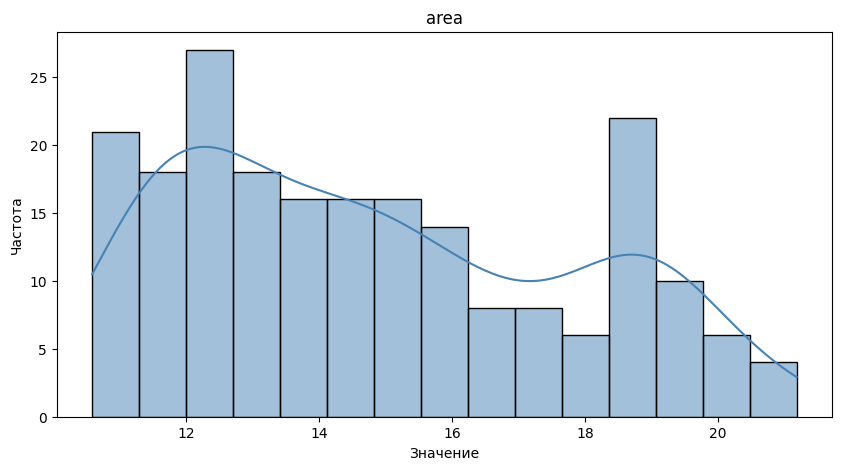

Признак: area
Статистика KS: 0.1068
p-value: 0.0010
Вывод: распределение статистически значимо отличается от нормального.



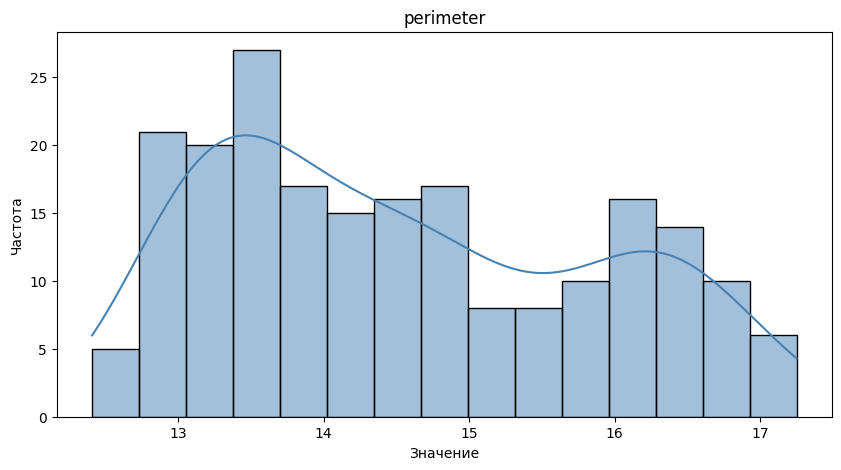

Признак: perimeter
Статистика KS: 0.1065
p-value: 0.0010
Вывод: распределение статистически значимо отличается от нормального.



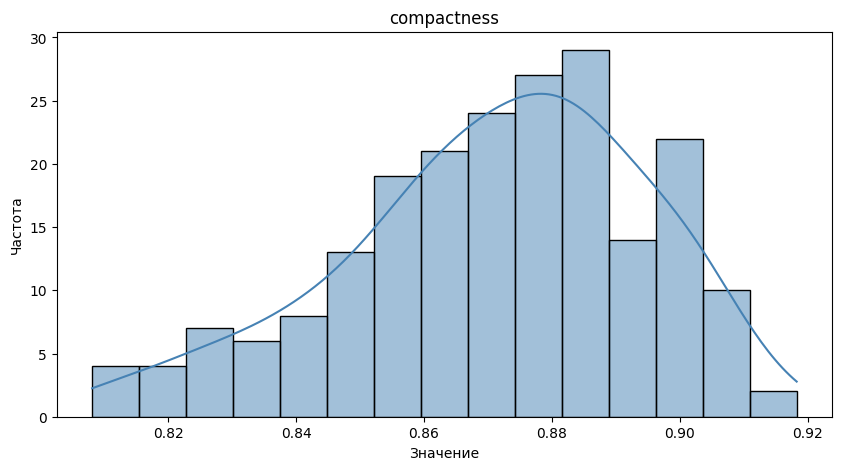

Признак: compactness
Статистика KS: 0.0625
p-value: 0.0497
Вывод: распределение статистически значимо отличается от нормального.



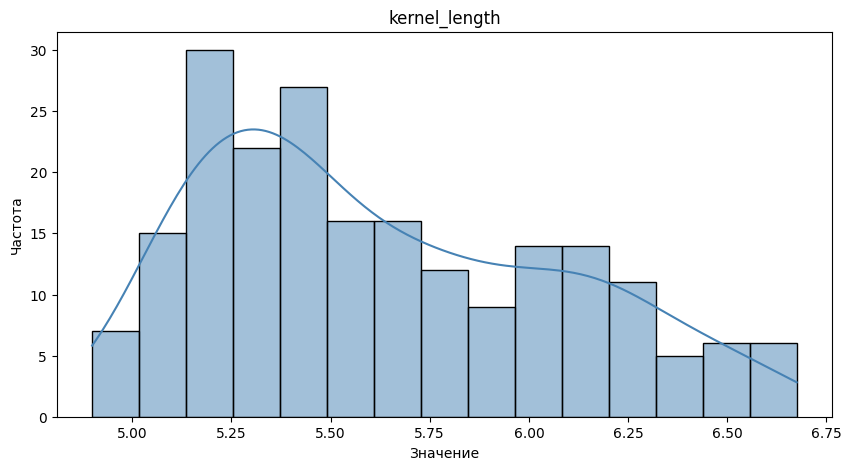

Признак: kernel_length
Статистика KS: 0.1192
p-value: 0.0010
Вывод: распределение статистически значимо отличается от нормального.



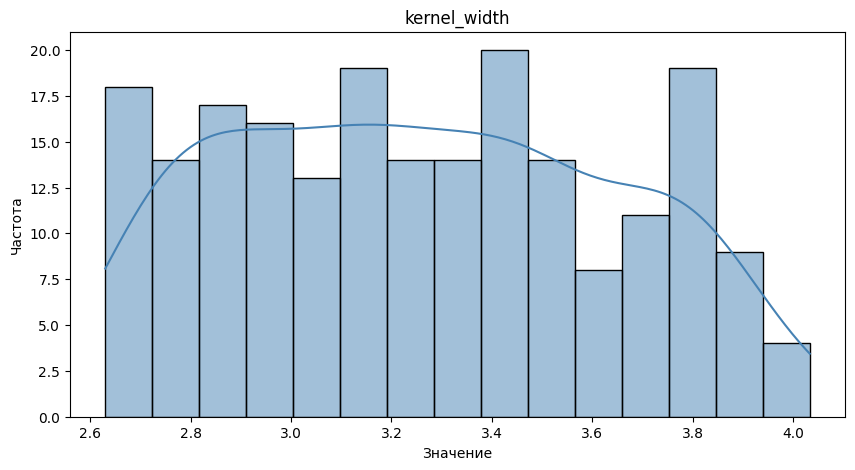

Признак: kernel_width
Статистика KS: 0.0689
p-value: 0.0203
Вывод: распределение статистически значимо отличается от нормального.



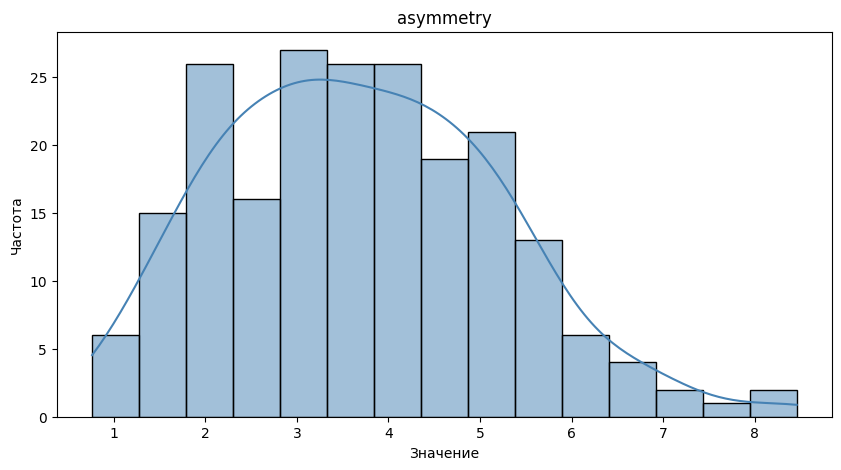

Признак: asymmetry
Статистика KS: 0.0483
p-value: 0.2953
Вывод: нет оснований отклонять гипотезу о нормальности.



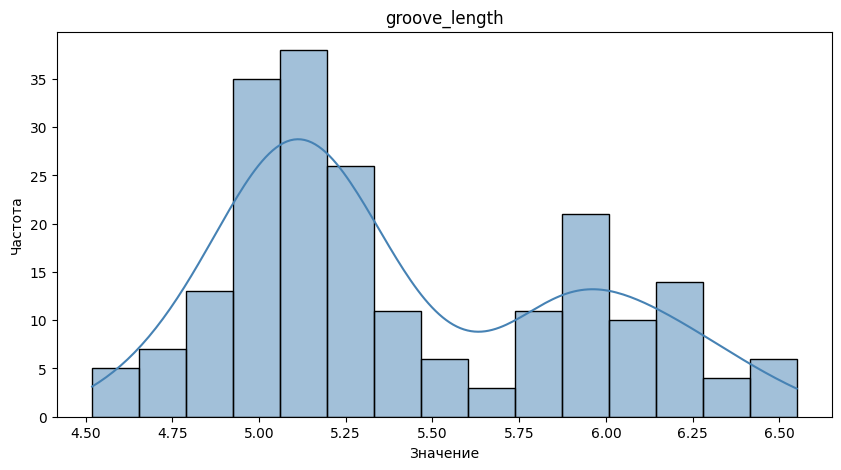

Признак: groove_length
Статистика KS: 0.1648
p-value: 0.0010
Вывод: распределение статистически значимо отличается от нормального.



In [37]:
for column in features.columns:
    stat, p = lilliefors(features[column], dist='norm')

    plt.figure(figsize=(10, 5))

    sns.histplot(
        features[column],
        bins=15,
        kde=True,
        color='steelblue'
    )

    plt.title(column)
    plt.xlabel('Значение')
    plt.ylabel('Частота')
    plt.show()

    print(f'Признак: {column}')
    print(f'Статистика KS: {stat:.4f}')
    print(f'p-value: {p:.4f}')

    if p >= 0.05:
        print('Вывод: нет оснований отклонять гипотезу о нормальности.')
    else:
        print('Вывод: распределение статистически значимо отличается от нормального.')

    print()

По результатам критерия Колмогорова — Смирнова с поправкой Лиллиефорса при уровне значимости α = 0.05 нормальность распределения отклоняется для 6 из 7 признаков.

Единственным признаком, для которого нет оснований отклонять гипотезу о нормальности, является **asymmetry** (p = 0.2953). Для признака **compactness** результат находится на границе уровня значимости (p = 0.0497).

Таким образом, большинство признаков не соответствуют нормальному распределению.

### Оценка информационной значимости признаков

**Корреляционный анализ**

Для предварительной оценки информативности признаков проведём корреляционный анализ с использованием парного коэффициента линейной корреляции Пирсона.

Значения коэффициента корреляции находятся в диапазоне от −1 до 1. Чем ближе абсолютное значение коэффициента к 1, тем сильнее линейная связь между признаками.

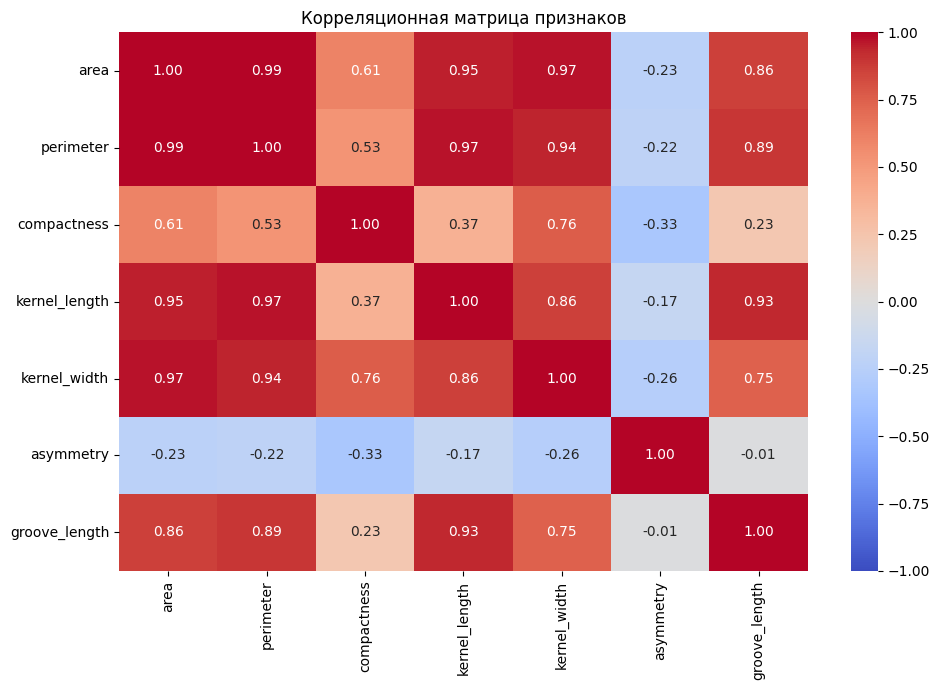

In [38]:
correlation = features.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

Корреляционный анализ выявил сильные положительные связи между признаками, характеризующими размеры зерна. Наибольшая корреляция наблюдается между area и perimeter (r = 0.99), perimeter и kernel_length (r = 0.97), area и kernel_width (r = 0.97).

**Оценка информативности признаков с помощью ANOVA F-score**

Для оценки способности признаков различать известные сорта пшеницы используем однофакторный дисперсионный анализ (ANOVA F-score).

Метод сравнивает межгрупповую и внутригрупповую изменчивость каждого признака. Чем выше значение F-score, тем сильнее различаются средние значения признака между сортами относительно разброса внутри сортов.

Метки классов используются исключительно для оценки информативности признаков и не участвуют в обучении моделей кластеризации.

In [39]:
X = features
y = data['class']

f_scores, p_values = f_classif(X, y)

anova_results = pd.DataFrame({
    'Признак': X.columns,
    'F-score': f_scores,
    'p-value': p_values
}).sort_values('F-score', ascending=False)

display(anova_results.round(4))

,Признак,F-score,p-value
0,area,548.1865,0.0
1,perimeter,541.5795,0.0
4,kernel_width,406.3020,0.0
6,groove_length,368.9500,0.0
3,kernel_length,322.1859,0.0
2,compactness,75.8690,0.0
5,asymmetry,51.8881,0.0


По результатам ANOVA F-score все семь признаков статистически значимо различаются между известными сортами пшеницы (p-value < 0.05). Наиболее высокие значения F-score получены для area (548.19), perimeter (541.58) и kernel_width (406.30). Наименьшие — для compactness (75.87) и asymmetry (51.89).

Таким образом, признаки, характеризующие размеры зерна, обладают высокой разделяющей способностью, но частично дублируют друг друга. Признаки compactness и asymmetry менее информативны по F-score, однако могут содержать дополнительную информацию о форме зерна.

Для дальнейшей кластеризации принято решение сохранить все 7 признаков, поскольку каждый из них потенциально полезен для описания объектов.

### Проверка выбросов

Для выявления потенциальных выбросов используем **метод межквартильного размаха (IQR)** и диаграммы «ящик с усами».

Значения считаются потенциальными выбросами, если они выходят за границы:

- Нижняя граница: Q1 − 1.5 × IQR
- Верхняя граница: Q3 + 1.5 × IQR

где IQR = Q3 − Q1 — межквартильный размах.

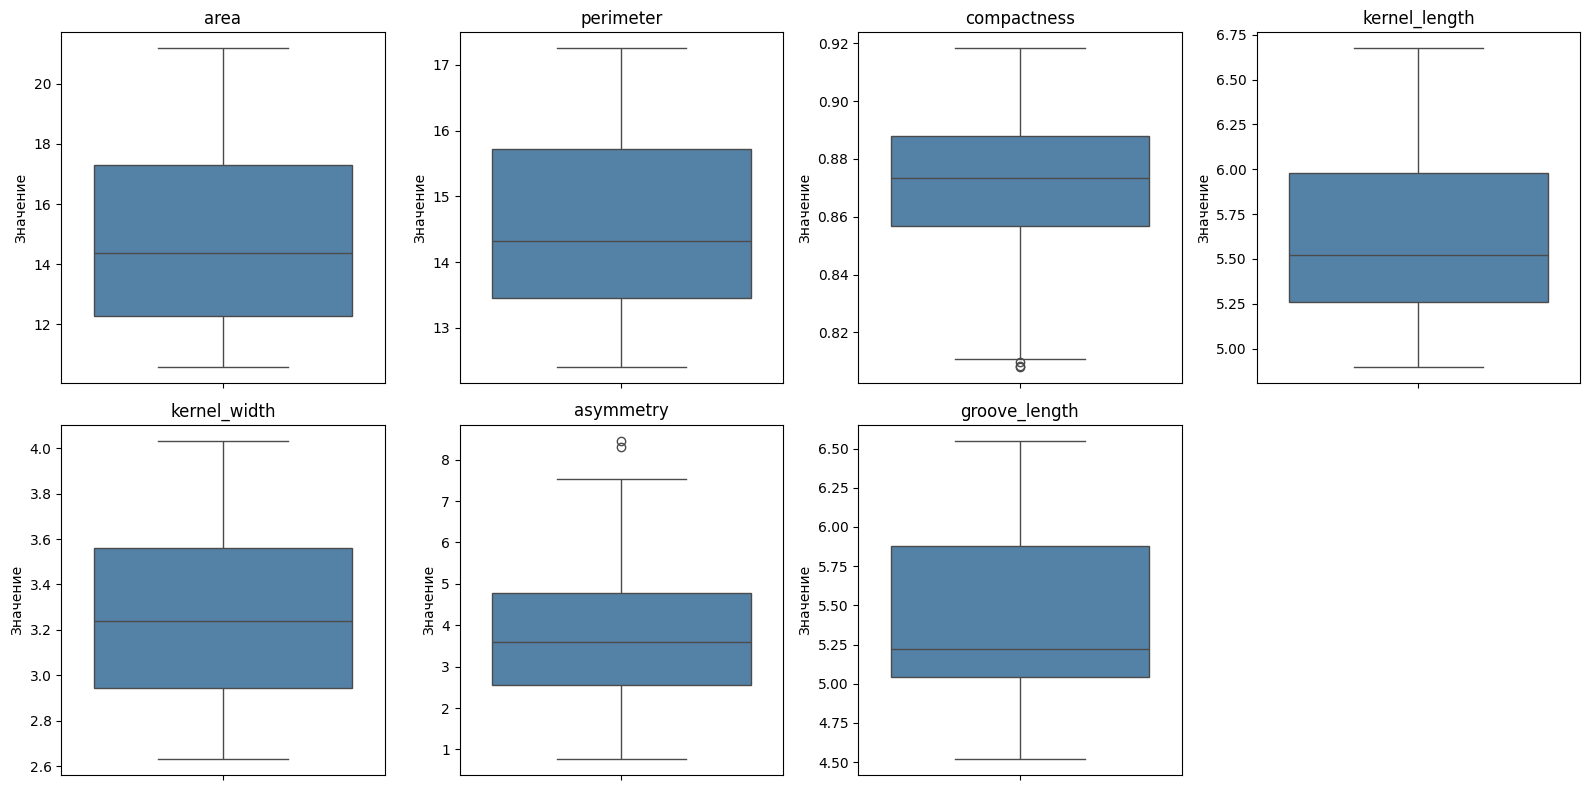

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, column in enumerate(features.columns):
    sns.boxplot(
        y=features[column],
        color='steelblue',
        ax=axes[i]
    )
    axes[i].set_title(column)
    axes[i].set_ylabel('Значение')

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [41]:
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

outliers = (features < Q1 - 1.5 * IQR) | (features > Q3 + 1.5 * IQR)

outlier_counts = outliers.sum()

display(pd.DataFrame({
    'Признак': features.columns,
    'Количество выбросов': outlier_counts.values,
    'Доля, %': (outlier_counts.values / len(features) * 100).round(2)
}))

,Признак,Количество выбросов,"Доля, %"
0,area,0,0.00
1,perimeter,0,0.00
2,compactness,3,1.43
3,kernel_length,0,0.00
4,kernel_width,0,0.00
5,asymmetry,2,0.95
6,groove_length,0,0.00


Методом межквартильного размаха (IQR) выявлено 5 объектов с потенциальными выбросами (2.38% наблюдений). Из них 3 обнаружены по признаку compactness и 2 — по признаку asymmetry. В остальных признаках выбросы отсутствуют.

Поскольку доля выбросов невелика, а их значения могут отражать естественные особенности формы зёрен, принято решение сохранить все 210 наблюдений. Метод IQR выявляет статистически необычные значения, но не свидетельствует об ошибках измерения. Удаление таких объектов без достаточных оснований может привести к потере полезной информации о структуре данных.

Таким образом, дополнительная обработка выбросов не требуется.

### Проверка условий применения кластеризации

Перед применением алгоритмов кластеризации проверим основные условия:

1. **Отсутствие заранее заданных классов.** Датасет Seeds содержит метки трёх сортов пшеницы, однако при кластеризации они не используются. Разбиение объектов на группы будет выполняться исключительно на основе семи числовых признаков. Метки классов могут применяться для последующей внешней оценки качества.

2. **Осмысленность кластеризации.** Признаки описывают геометрические характеристики зёрен пшеницы. Объекты могут иметь сходные размеры и форму, поэтому их группировка по этим характеристикам имеет практический смысл. Анализ распределений и корреляций также показал наличие структуры в данных.

3. **Отсутствие существенных выбросов.** Методом IQR выявлено 5 потенциальных выбросов (2.38% наблюдений). Их небольшая доля и возможное естественное происхождение не дают достаточных оснований для удаления. Все наблюдения сохранены.

**Вывод:** датасет Seeds подходит для применения методов кластеризации. Для построения кластеров будут использоваться 7 числовых признаков без меток классов. Перед применением алгоритмов необходимо выполнить масштабирование признаков.

## 2. Подготовка данных к кластеризации

### Стандартизация признаков

Поскольку числовые признаки имеют разные масштабы, выполним стандартизацию с помощью StandardScaler.

Метод преобразует каждый признак таким образом, чтобы его среднее значение было равно 0, а стандартное отклонение — 1. Это позволяет привести признаки к сопоставимому масштабу и уменьшить влияние различий в единицах измерения на результаты кластеризации.

Стандартизация выполняется для всех 7 числовых признаков без учёта меток классов.

In [42]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns
)

display(X_scaled.head())

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,0.142098,0.215462,0.000061,0.304218,0.141702,-0.986152,-0.383577
1,0.011188,0.008224,0.428515,-0.168625,0.197432,-1.788166,-0.922013
2,-0.192067,-0.360201,1.442383,-0.763637,0.208048,-0.667479,-1.189192
3,-0.347091,-0.475333,1.039381,-0.688978,0.319508,-0.960818,-1.229983
4,0.445257,0.330595,1.374509,0.066666,0.805159,-1.563495,-0.475356


In [43]:
print("Средние значения:")
print(X_scaled.mean().round(3))

print("\nСтандартные отклонения:")
print(X_scaled.std(ddof=0).round(3))

Средние значения:
area            -0.0
perimeter        0.0
compactness      0.0
kernel_length   -0.0
kernel_width    -0.0
asymmetry       -0.0
groove_length   -0.0
dtype: float64

Стандартные отклонения:
area             1.0
perimeter        1.0
compactness      1.0
kernel_length    1.0
kernel_width     1.0
asymmetry        1.0
groove_length    1.0
dtype: float64


Средние значения всех 7 признаков после преобразования равны 0, а стандартные отклонения — 1. Таким образом, признаки приведены к сопоставимому масштабу, что позволяет уменьшить влияние различий в их исходных значениях на результаты кластеризации. 

### Визуальная оценка структуры данных

Для предварительной оценки кластерной структуры построим матрицу диаграмм рассеивания по стандартизированным признакам.

Матрица позволит оценить взаимное расположение объектов, выявить возможные группы и предположить количество и форму кластеров.

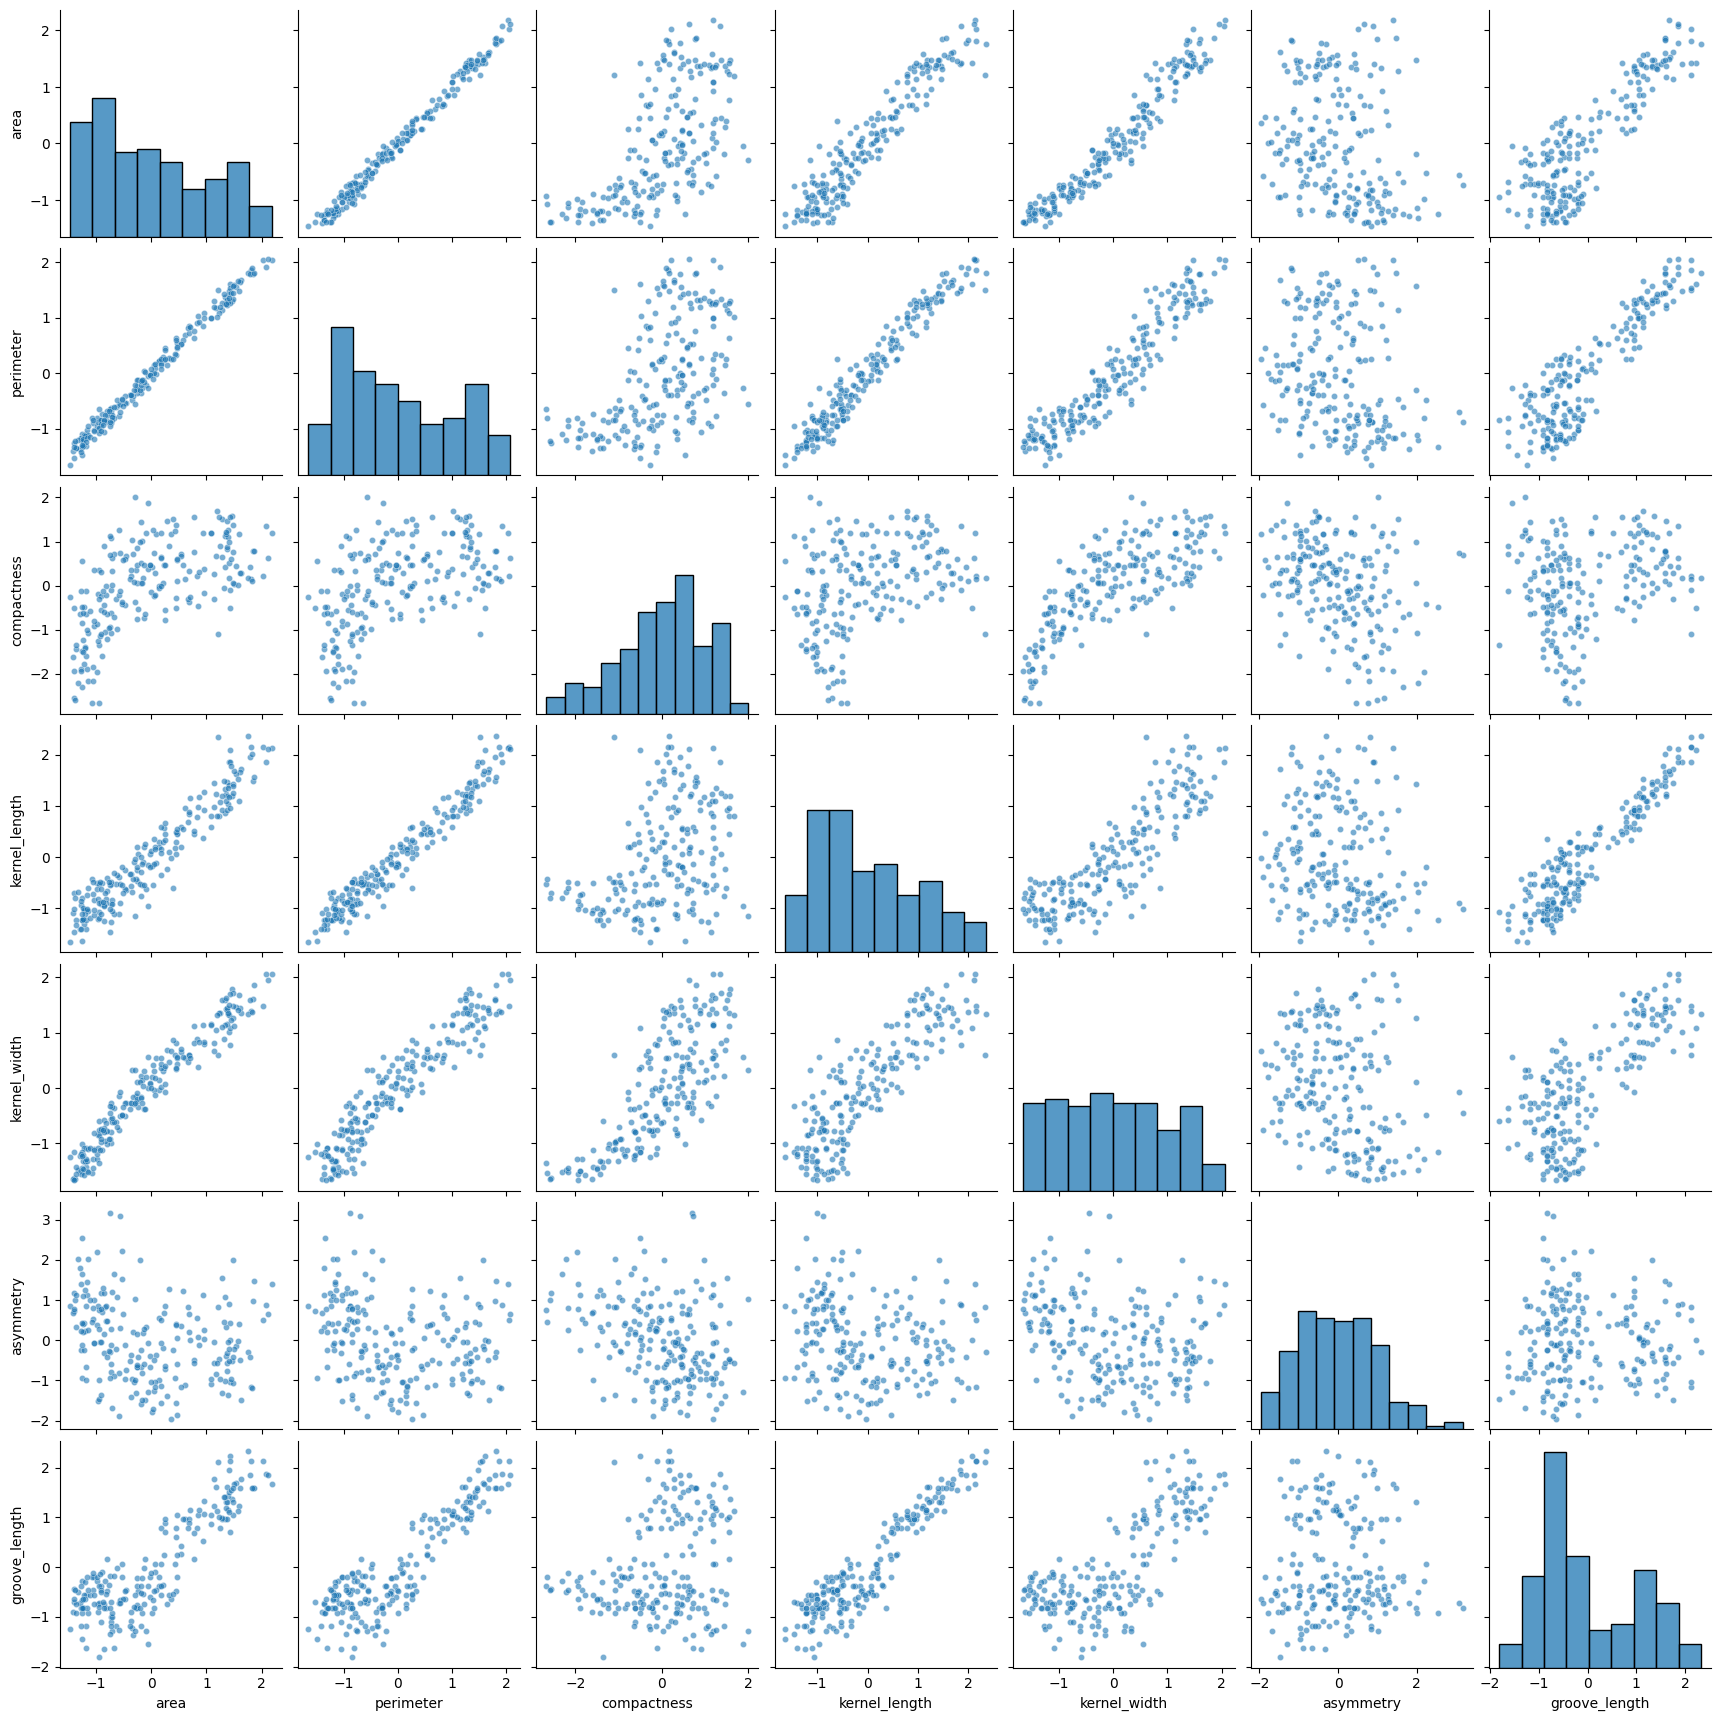

In [44]:
sns.pairplot(
    X_scaled,
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 20}
)

plt.show()

**Вывод:** матрица диаграмм рассеивания показала наличие выраженных зависимостей между рядом признаков. Объекты преимущественно образуют вытянутые облака точек, что свидетельствует о коррелированности признаков.

На отдельных диаграммах наблюдаются области повышенной плотности объектов, однако чёткие границы между предполагаемыми кластерами отсутствуют. Поэтому однозначно определить количество кластеров визуально затруднительно.

Характер распределения позволяет предположить наличие кластеров вытянутой формы. Для дальнейшего исследования целесообразно использовать **K-means и Gaussian Mixture Model (GMM)**. K-means позволит получить разбиение на основе расстояний до центров кластеров, а GMM — учитывать возможную эллиптическую форму кластеров.

## 3. Реализация методов кластеризации

### Выбор методов кластеризации

Для исследования выбраны два алгоритма:

- **K-means** — метод, основанный на минимизации расстояний объектов до центроидов кластеров. Подходит для выделения компактных групп и будет использоваться как базовый алгоритм.
- **Gaussian Mixture Model (GMM)** — вероятностный метод, предполагающий представление данных в виде смеси многомерных нормальных распределений. Обучается с помощью EM-алгоритма и позволяет моделировать кластеры эллиптической формы.

Выбор GMM обусловлен наличием вытянутых и частично перекрывающихся облаков точек на матрице диаграмм рассеивания.

### Определение оптимального количества кластеров для K-means

Для выбора количества кластеров используем два метода:

- **Метод локтя** — анализирует зависимость суммы квадратов расстояний объектов до центроидов (inertia) от количества кластеров. Оптимальное значение определяется в точке, после которой уменьшение inertia замедляется.
- **Метод силуэта** — оценивает компактность и разделённость кластеров. Коэффициент силуэта принимает значения от −1 до 1, при этом более высокие значения свидетельствуют о лучшем разделении кластеров.

Совместное применение методов позволит обоснованно выбрать количество кластеров для K-means.

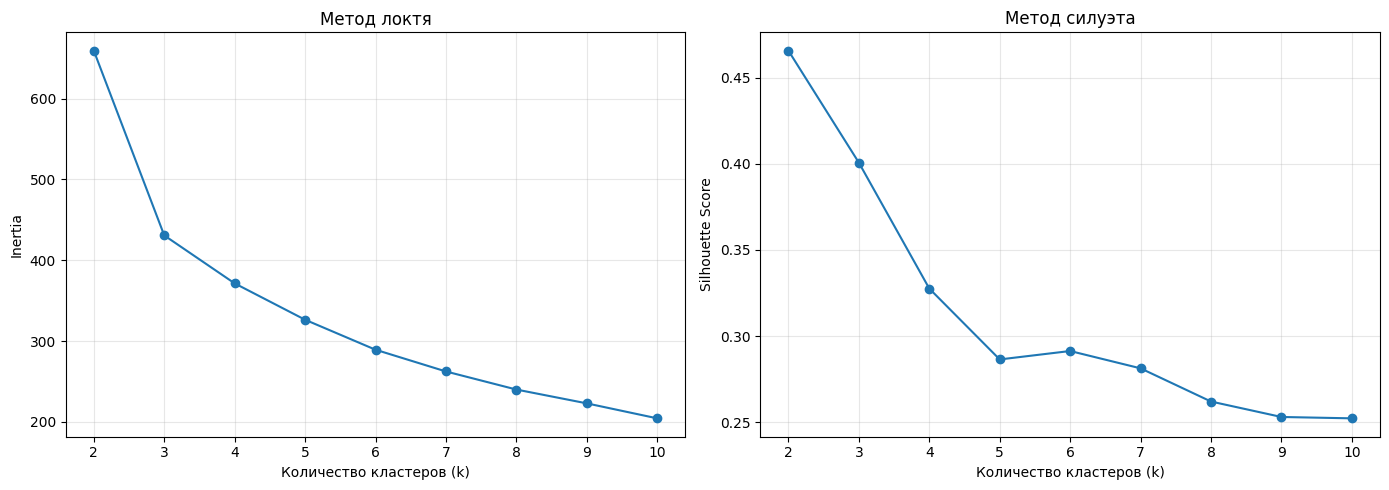

In [45]:
k_values = range(2, 11)

inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(k_values)
axes[0].grid(alpha=0.3)

axes[1].plot(k_values, silhouettes, marker='o')
axes[1].set_title('Метод силуэта')
axes[1].set_xlabel('Количество кластеров (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(k_values)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Вывод:** на графике метода локтя наблюдается перегиб при k = 3, после которого снижение inertia заметно замедляется.

Метод силуэта показывает максимальное значение при k = 2 (около 0.465), тогда как при k = 3 коэффициент составляет 0.401.

Для дальнейшей кластеризации выбрано **k = 3**, поскольку этому значению соответствует перегиб на графике метода локтя. Такое разбиение также позволяет выделить более детальную структуру данных, несмотря на более высокий коэффициент силуэта при k = 2.




### Кластеризация методом K-means

**K-means (метод K-средних)** — алгоритм кластеризации, который разделяет объекты на заданное количество кластеров на основе их близости к центроидам.

**Принцип работы алгоритма:**

1. Выбирается количество кластеров k и задаются начальные центроиды.
2. Каждый объект относится к кластеру с ближайшим центроидом.
3. Центроиды пересчитываются как средние значения объектов соответствующих кластеров.
4. Шаги 2–3 повторяются до сходимости алгоритма.

**Целевая функция K-means:**

$$
J = \sum_{i=1}^{k} \sum_{x \in C_i} \|x-\mu_i\|^2
$$

где:

- $k$ — количество кластеров;
- $C_i$ — множество объектов i-го кластера;
- $x$ — вектор признаков объекта;
- $\mu_i$ — центроид i-го кластера;
- $\|x-\mu_i\|^2$ — квадрат евклидова расстояния между объектом и центроидом.

**Цель алгоритма** — минимизировать сумму квадратов расстояний объектов до центроидов своих кластеров, обеспечивая компактность полученных групп.

На основании метода локтя и анализа коэффициента силуэта выбрано **k = 3**.

Кластеризация выполняется по всем 7 стандартизированным признакам без использования известных меток классов. Для повышения устойчивости результата алгоритм запускается несколько раз с различными начальными центроидами.


In [46]:
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=20,
    random_state=42
)

labels_kmeans = kmeans.fit_predict(X_scaled)

print("Количество объектов в кластерах:")
print(pd.Series(labels_kmeans).value_counts().sort_index())

print("\nЦентры кластеров:")
display(pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features.columns
).round(3))

print("\nInertia:", round(kmeans.inertia_, 3))

Количество объектов в кластерах:
0    72
1    67
2    71
Name: count, dtype: int64

Центры кластеров:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,-1.030,-1.007,-0.965,-0.898,-1.086,0.695,-0.625
1,1.257,1.262,0.560,1.238,1.165,-0.045,1.292
2,-0.141,-0.170,0.450,-0.258,0.002,-0.662,-0.586



Inertia: 430.659


**Вывод:** алгоритм K-means разделил 210 объектов на 3 кластера. В первый кластер (0) вошло 72 объекта, во второй (1) — 67, в третий (2) — 71.

Полученные кластеры имеют приблизительно одинаковую численность, что свидетельствует об отсутствии выраженного дисбаланса между группами.

Также получены координаты центроидов кластеров в стандартизированном масштабе и итоговое значение целевой функции Inertia, представляющее собой сумму квадратов расстояний объектов до центроидов соответствующих кластеров.


### Кластеризация методом Gaussian Mixture Model (GMM)

**Gaussian Mixture Model (GMM)** — вероятностный метод кластеризации, представляющий данные в виде смеси нескольких многомерных нормальных распределений.

В отличие от K-means, GMM оценивает вероятность принадлежности каждого объекта к каждому кластеру и позволяет учитывать различия в форме и размерах кластеров.

**Математическая модель:**

$$
p(x) = \sum_{i=1}^{k} \pi_i \mathcal{N}(x \mid \mu_i, \Sigma_i)
$$

где:

- $k$ — количество гауссовских компонентов;
- $\pi_i$ — вес i-го компонента;
- $\mu_i$ — вектор средних значений;
- $\Sigma_i$ — ковариационная матрица;
- $\mathcal{N}$ — плотность многомерного нормального распределения.

**Обучение GMM выполняется с помощью EM-алгоритма (Expectation-Maximization):**

1. **Инициализация:** задаются начальные параметры компонентов.
2. **E-шаг (Expectation):** вычисляются вероятности принадлежности объектов к компонентам.
3. **M-шаг (Maximization):** обновляются веса, средние значения и ковариационные матрицы компонентов.
4. **Повторение:** шаги E и M повторяются до сходимости алгоритма.


Для сопоставимости с K-means выбрано **3 гауссовских компонента**.

Используется полная ковариационная матрица (**covariance_type = full**), позволяющая моделировать кластеры эллиптической формы и учитывать корреляции между признаками.

Обучение выполняется по всем 7 стандартизированным признакам без использования известных меток классов.


In [47]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type='full',
    n_init=10,
    random_state=42
)

labels_gmm = gmm.fit_predict(X_scaled)

print("Количество объектов в кластерах:")
print(pd.Series(labels_gmm).value_counts().sort_index())

Количество объектов в кластерах:
0    65
1    85
2    60
Name: count, dtype: int64


**Вывод:** алгоритм GMM разделил 210 объектов на 3 кластера, содержащих 65, 85 и 60 наблюдений соответственно.

Распределение объектов по кластерам оказалось менее равномерным, чем при использовании K-means. Это объясняется различиями в принципах работы алгоритмов: GMM учитывает вероятностную принадлежность объектов к компонентам и их ковариационную структуру.


### Проверка сходимости модели и вероятностей принадлежности к компонентам

Для оценки сходимости модели GMM используются атрибуты converged_ и n_iter_, позволяющие определить, достиг ли EM-алгоритм сходимости и за какое количество итераций.

Для получения вероятностей принадлежности объектов к компонентам используется метод predict_proba(). Итоговая метка каждого объекта определяется по компоненте с максимальной вероятностью принадлежности.

In [48]:
print("Сходимость модели:", gmm.converged_)
print("Количество итераций:", gmm.n_iter_)

probabilities_gmm = gmm.predict_proba(X_scaled)

probabilities_df = pd.DataFrame(
    probabilities_gmm,
    columns=['Компонента 0', 'Компонента 1', 'Компонента 2']
)

probabilities_df['Кластер'] = probabilities_gmm.argmax(axis=1)

print("\nВероятности принадлежности к компонентам:")
display(probabilities_df.sample(5, random_state=42).round(3))

Сходимость модели: True
Количество итераций: 17

Вероятности принадлежности к компонентам:


,Компонента 0,Компонента 1,Компонента 2,Кластер
30,0.0,0.995,0.005,1
172,0.0,1.000,0.000,1
84,1.0,0.000,0.000,0
199,0.0,1.000,0.000,1
60,0.0,1.000,0.000,1


**Вывод:** модель GMM достигла сходимости за 17 итераций EM-алгоритма.

Для пяти случайно выбранных объектов получены вероятности принадлежности к каждой из трёх компонент модели GMM. Итоговые метки кластеров определены по максимальной вероятности принадлежности.

Для объекта с индексом 30 вероятность принадлежности к компоненте 1 составляет 99,5%, а к компоненте 2 — 0,5%, поэтому объект отнесён к кластеру 1.

Для остальных представленных объектов максимальные вероятности принадлежности после округления составляют 100%. Полученные результаты свидетельствуют о высокой уверенности модели при распределении рассмотренных объектов по кластерам.


## 4. Оценка качества кластеризации

### Внутренние метрики качества

Для оценки качества кластеризации используем три внутренние метрики, не требующие знания истинных классов объектов.

**1. Коэффициент силуэта (Silhouette Score)**

Оценивает, насколько объект близок к своему кластеру по сравнению с ближайшим соседним кластером.

$$
s(i) = \frac{b(i)-a(i)}{\max(a(i),b(i))}
$$

где:

- $a(i)$ — среднее расстояние от объекта до остальных объектов своего кластера;
- $b(i)$ — минимальное среднее расстояние от объекта до объектов другого кластера.

Значения находятся в диапазоне от −1 до 1. Чем ближе к 1, тем лучше разделены кластеры.

**2. Индекс Калински — Харабаша (Calinski–Harabasz Index)**

Оценивает соотношение межкластерного и внутрикластерного разброса.

$$
CH = \frac{B_k/(k-1)}{W_k/(n-k)}
$$

где:

- $B_k$ — межкластерная сумма квадратов отклонений;
- $W_k$ — внутрикластерная сумма квадратов отклонений;
- $k$ — количество кластеров;
- $n$ — количество объектов.

Чем выше значение индекса, тем лучше выражена кластерная структура.

**3. Индекс Дэвиса — Болдина (Davies–Bouldin Index)**

Оценивает среднее сходство каждого кластера с наиболее похожим на него другим кластером.

$$
DB = \frac{1}{k}\sum_{i=1}^{k}\max_{j\ne i}\left(\frac{S_i+S_j}{M_{ij}}\right)
$$

где:

- $S_i$, $S_j$ — средние расстояния объектов до центров соответствующих кластеров;
- $M_{ij}$ — расстояние между центрами кластеров;
- $k$ — количество кластеров.

Чем ниже значение индекса, тем лучше разделены кластеры.

In [49]:
results = pd.DataFrame({
    'Метод': ['K-means', 'GMM'],
    'Silhouette': [
        silhouette_score(X_scaled, labels_kmeans),
        silhouette_score(X_scaled, labels_gmm)
    ],
    'Calinski-Harabasz': [
        calinski_harabasz_score(X_scaled, labels_kmeans),
        calinski_harabasz_score(X_scaled, labels_gmm)
    ],
    'Davies-Bouldin': [
        davies_bouldin_score(X_scaled, labels_kmeans),
        davies_bouldin_score(X_scaled, labels_gmm)
    ]
})

display(results.round(3))

,Метод,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-means,0.401,249.784,0.928
1,GMM,0.363,224.453,0.988



**Вывод:** по результатам внутренней оценки качества K-means показал лучшие результаты по всем трём метрикам.

Коэффициент силуэта составил 0.401 против 0.363 у GMM, индекс Калински — Харабаша — 249.784 против 224.453, а индекс Дэвиса — Болдина — 0.928 против 0.988.

Таким образом, кластеры K-means характеризуются лучшей компактностью и разделённостью по выбранным внутренним метрикам.




### Анализ компактности и расстояний

Для более подробной оценки качества кластеризации рассмотрим внутрикластерные и межкластерные расстояния.

**1. Внутрикластерное расстояние**

Характеризует компактность кластера и рассчитывается как среднее евклидово расстояние объектов до его центра.

$$
D_{\text{intra}}(C_i) = \frac{1}{n_i}\sum_{x \in C_i}\|x-\mu_i\|
$$

где:

- $C_i$ — множество объектов i-го кластера;
- $n_i$ — количество объектов в кластере;
- $x$ — вектор признаков объекта;
- $\mu_i$ — центр кластера.

Чем меньше значение, тем компактнее кластер.

**2. Межкластерное расстояние**

Характеризует удалённость кластеров и рассчитывается как евклидово расстояние между их центрами.

$$
D_{\text{inter}}(C_i,C_j) = \|\mu_i-\mu_j\|
$$

где:

- $\mu_i$, $\mu_j$ — центры двух различных кластеров.

Чем больше расстояние между центрами, тем дальше расположены кластеры.


In [50]:
for name, labels in [('K-means', labels_kmeans), ('GMM', labels_gmm)]:
    centers = X_scaled.groupby(labels).mean()

    compactness = [
        np.linalg.norm(
            X_scaled[labels == i].values - centers.loc[i].values,
            axis=1
        ).mean()
        for i in centers.index
    ]

    print(f'\n{name}: компактность кластеров')
    display(pd.DataFrame({
        'Кластер': centers.index,
        'Количество объектов': [sum(labels == i) for i in centers.index],
        'Среднее расстояние до центра': compactness
    }).round(3))

    distances = pd.DataFrame(
        squareform(pdist(centers)),
        index=centers.index,
        columns=centers.index
    )

    print(f'{name}: расстояния между центрами')
    display(distances.round(3))


K-means: компактность кластеров


,Кластер,Количество объектов,Среднее расстояние до центра
0,0,72,1.300
1,1,67,1.366
2,2,71,1.321


K-means: расстояния между центрами


,0,1,2
0,0.000,5.153,2.632
1,5.153,0.000,3.393
2,2.632,3.393,0.000



GMM: компактность кластеров


,Кластер,Количество объектов,Среднее расстояние до центра
0,0,65,1.374
1,1,85,1.440
2,2,60,1.261


GMM: расстояния между центрами


,0,1,2
0,0.000,5.057,3.049
1,5.057,0.000,2.573
2,3.049,2.573,0.000



**Вывод:** анализ внутрикластерных расстояний показал, что у K-means наиболее компактным является кластер 0 (1.300), а у GMM — кластер 2 (1.261). При этом у K-means компактность трёх кластеров более равномерна.

Анализ межкластерных расстояний показал, что наиболее удалены друг от друга кластеры 0 и 1 у обоих методов с учётом различий в нумерации: у K-means расстояние составляет 5.153, у GMM — 5.057. Эти группы соответствуют мелким и крупным зёрнам.

Наиболее близкими оказались кластеры 0 и 2 у K-means (2.632) и кластеры 1 и 2 у GMM (2.573).

Таким образом, оба метода выделяют схожую структуру данных, однако K-means формирует более равномерные по компактности группы.



### Внешние метрики качества кластеризации

Внешние метрики позволяют оценить соответствие полученных кластеров известным классам объектов.

В датасете Seeds присутствуют метки трёх сортов пшеницы, которые не использовались при обучении алгоритмов, но могут применяться для независимой оценки результатов.

Для сравнения K-means и GMM используем шесть внешних метрик.

**1. Индекс Ренда (Rand Index, RI)**

Оценивает долю пар объектов, для которых кластеризация согласуется с истинным разбиением.

$$
RI = \frac{TP + TN}{TP + TN + FP + FN}
$$

где:

- $TP$ — пары объектов, находящиеся в одном классе и одном кластере;
- $TN$ — пары объектов, находящиеся в разных классах и разных кластерах;
- $FP$ — пары объектов, находящиеся в разных классах, но одном кластере;
- $FN$ — пары объектов, находящиеся в одном классе, но разных кластерах.

Чем ближе RI к 1, тем выше согласованность разбиений.

**2. Скорректированный индекс Ренда (Adjusted Rand Index, ARI)**

Учитывает возможность случайного совпадения двух разбиений.

$$
ARI = \frac{RI - E[RI]}{1 - E[RI]}
$$

где $E[RI]$ — ожидаемое значение индекса Ренда при случайном разбиении с фиксированными размерами групп.

Значение 1 соответствует полному совпадению, 0 — случайному уровню согласованности, отрицательные значения — согласованности ниже случайной.

**3. Нормализованная взаимная информация (NMI)**

Измеряет количество общей информации между истинными классами и полученными кластерами.

$$
NMI = \frac{2I(U;V)}{H(U)+H(V)}
$$

где:

- $I(U;V)$ — взаимная информация между разбиениями;
- $H(U)$, $H(V)$ — энтропии истинных классов и кластеров.

Чем ближе NMI к 1, тем сильнее соответствие разбиений.

**4. Однородность (Homogeneity)**

Показывает, насколько каждый кластер состоит из объектов одного истинного класса.

$$
h = 1 - \frac{H(U|V)}{H(U)}
$$

где $H(U|V)$ — условная энтропия классов при известном разбиении на кластеры.

Значение 1 означает, что каждый кластер содержит объекты только одного класса.

**5. Полнота (Completeness)**

Показывает, насколько объекты одного истинного класса сосредоточены в одном кластере.

$$
c = 1 - \frac{H(V|U)}{H(V)}
$$

Значение 1 означает, что все объекты каждого класса находятся в одном кластере.

**6. V-мера (V-measure)**

Представляет собой гармоническое среднее однородности и полноты.

$$
V = \frac{2hc}{h+c}
$$

Чем ближе V-мера к 1, тем лучше баланс между однородностью и полнотой кластеризации.


In [51]:
y_true = data['class']

external_results = pd.DataFrame({
    'Метод': ['K-means', 'GMM'],
    'RI': [
        rand_score(y_true, labels_kmeans),
        rand_score(y_true, labels_gmm)
    ],
    'ARI': [
        adjusted_rand_score(y_true, labels_kmeans),
        adjusted_rand_score(y_true, labels_gmm)
    ],
    'NMI': [
        normalized_mutual_info_score(y_true, labels_kmeans),
        normalized_mutual_info_score(y_true, labels_gmm)
    ],
    'Homogeneity': [
        homogeneity_score(y_true, labels_kmeans),
        homogeneity_score(y_true, labels_gmm)
    ],
    'Completeness': [
        completeness_score(y_true, labels_kmeans),
        completeness_score(y_true, labels_gmm)
    ],
    'V-measure': [
        v_measure_score(y_true, labels_kmeans),
        v_measure_score(y_true, labels_gmm)
    ]
})

display(external_results.round(3))

,Метод,RI,ARI,NMI,Homogeneity,Completeness,V-measure
0,K-means,0.900,0.773,0.728,0.728,0.728,0.728
1,GMM,0.877,0.723,0.725,0.721,0.729,0.725



**Вывод:** по результатам оценки внешних метрик алгоритм K-means продемонстрировал несколько более высокое соответствие полученных кластеров известным сортам пшеницы.

Для K-means индекс Ренда составил 0.900, а скорректированный индекс Ренда — 0.773, что выше соответствующих значений GMM (0.877 и 0.723).

Показатели NMI, однородности и V-меры также оказались немного выше у K-means. При этом GMM незначительно превосходит K-means по полноте (0.729 против 0.728).

Таким образом, K-means показал лучшие результаты по большинству внешних метрик, что согласуется с ранее полученными результатами внутренней оценки качества кластеризации.



## 5. Исследование влияния параметров алгоритма K-means

Для исследования чувствительности алгоритма K-means рассмотрим влияние количества кластеров **k** на качество кластеризации.

Количество кластеров является одним из основных параметров K-means и определяет, на сколько групп будут разделены объекты.

Проведём эксперимент для значений **k от 2 до 10**, оценивая качество разбиения с помощью трёх внутренних метрик:

- **Silhouette Score** — оценивает компактность и разделённость кластеров.
- **Calinski–Harabasz Index** — характеризует соотношение межкластерного и внутрикластерного разброса.
- **Davies–Bouldin Index** — оценивает сходство кластеров с учётом их компактности и расстояний между центрами.

Это позволит определить, насколько качество кластеризации зависит от выбранного количества кластеров.


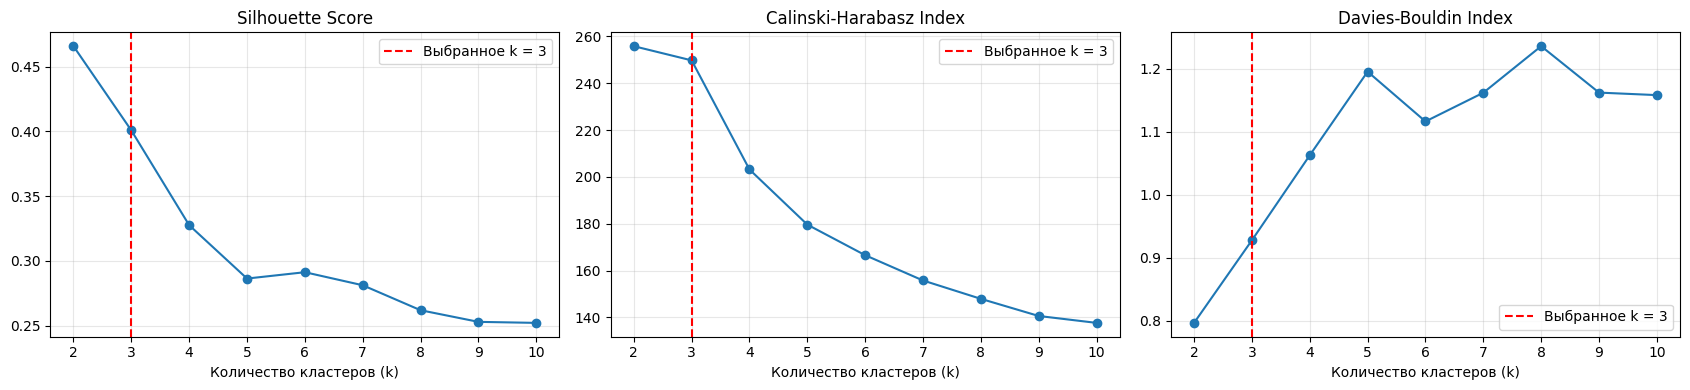

In [52]:
k_values = range(2, 11)

silhouettes = []
calinski_scores = []
davies_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X_scaled)

    silhouettes.append(silhouette_score(X_scaled, labels))
    calinski_scores.append(calinski_harabasz_score(X_scaled, labels))
    davies_scores.append(davies_bouldin_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

metrics = [
    ('Silhouette Score', silhouettes),
    ('Calinski-Harabasz Index', calinski_scores),
    ('Davies-Bouldin Index', davies_scores)
]

for ax, (title, values) in zip(axes, metrics):
    ax.plot(k_values, values, marker='o')
    ax.axvline(x=3, color='red', linestyle='--', label='Выбранное k = 3')
    ax.set_title(title)
    ax.set_xlabel('Количество кластеров (k)')
    ax.set_xticks(k_values)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


**Вывод:** изменение количества кластеров k существенно влияет на качество кластеризации методом K-means.

Наилучшие значения всех трёх внутренних метрик получены при k = 2. При увеличении количества кластеров коэффициент силуэта и индекс Калински — Харабаша преимущественно снижаются, а индекс Дэвиса — Болдина возрастает, что свидетельствует об ухудшении компактности и разделённости кластеров.

При этом выбранное ранее значение **k = 3** остаётся обоснованным с учётом результатов метода локтя и необходимости более детального разбиения данных.

Таким образом, алгоритм K-means чувствителен к выбору количества кластеров. По внутренним метрикам предпочтительно k = 2, однако для дальнейшего анализа сохраняется **k = 3**.


# 6. Визуализация кластеров с помощью PCA

Для визуального сравнения результатов K-means и GMM применим метод главных компонент (PCA).

PCA позволяет уменьшить размерность данных, сохраняя наибольшую возможную долю дисперсии для выбранного количества компонент.

Для построения двумерных диаграмм рассеивания используем две главные компоненты. На графиках выделим объекты различных кластеров цветом, а также отобразим центры кластеров.

Дисперсия двух компонент: 88.98 %


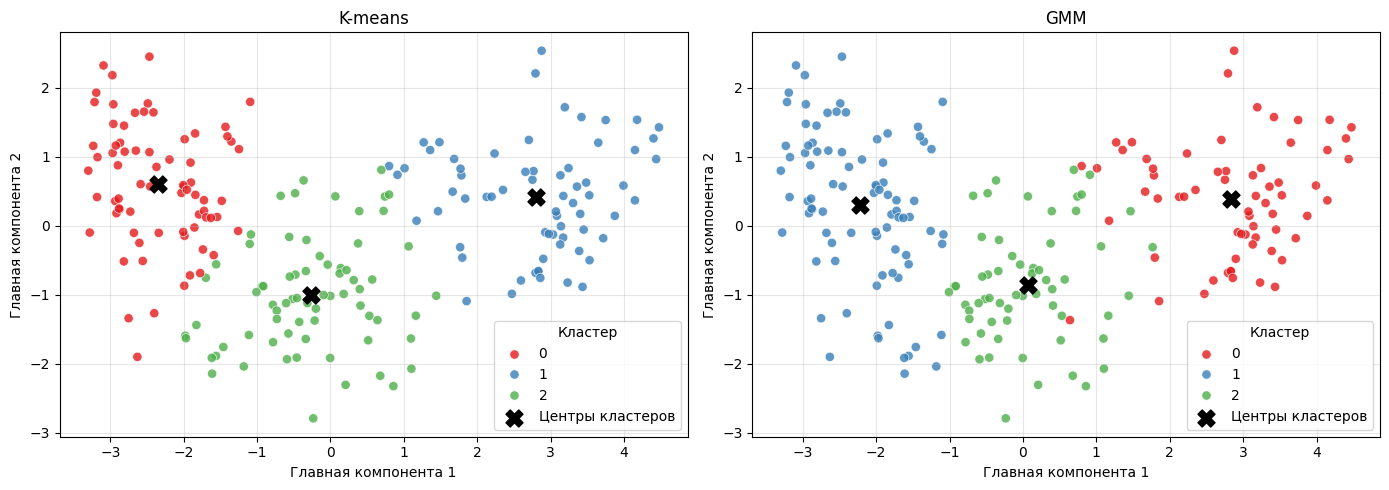

In [55]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

print('Дисперсия двух компонент:',
      round(pca_2d.explained_variance_ratio_.sum() * 100, 2), '%')

centers_kmeans_pca = pca_2d.transform(
    pd.DataFrame(kmeans.cluster_centers_, columns=X_scaled.columns)
)

centers_gmm_pca = pca_2d.transform(
    pd.DataFrame(gmm.means_, columns=X_scaled.columns)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, centers, title in zip(
    axes,
    [labels_kmeans, labels_gmm],
    [centers_kmeans_pca, centers_gmm_pca],
    ['K-means', 'GMM']
):
    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels,
        palette='Set1',
        s=45,
        alpha=0.8,
        ax=ax
    )

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        color='black',
        marker='X',
        s=150,
        label='Центры кластеров',
        zorder=5
    )

    ax.set_title(title)
    ax.set_xlabel('Главная компонента 1')
    ax.set_ylabel('Главная компонента 2')
    ax.legend(title='Кластер')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод:** первые две главные компоненты объясняют 88.98% дисперсии стандартизированных данных, что позволяет использовать их для двумерной визуализации результатов кластеризации.

На графиках обоих методов выделяются три основные группы объектов. Крайние группы достаточно хорошо разделены, тогда как центральная частично пересекается с соседними.

Центры кластеров обозначены чёрными крестами и расположены в областях скопления объектов соответствующих групп. Расположение центров для K-means и GMM схоже, однако наблюдаются небольшие различия в их координатах и распределении отдельных объектов между кластерами.

Кластеризация выполнена по всем семи стандартизированным признакам, а метод PCA использован исключительно для визуализации полученных результатов.


### Анализ центров кластеров

Для содержательной интерпретации выделенных групп рассмотрим центры кластеров, полученных методами K-means и GMM.

Поскольку кластеризация выполнялась на стандартизированных данных, восстановим исходные значения признаков с помощью обратного преобразования StandardScaler.

Для K-means используем координаты центроидов, а для GMM — средние векторы гауссовских компонентов.


In [54]:
centers_kmeans = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features.columns
)

centers_gmm = pd.DataFrame(
    scaler.inverse_transform(gmm.means_),
    columns=features.columns
)

print('Центры кластеров K-means:')
display(centers_kmeans.round(3))

print('Центры кластеров GMM:')
display(centers_gmm.round(3))

Центры кластеров K-means:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,11.857,13.248,0.848,5.232,2.850,4.742,5.102
1,18.495,16.203,0.884,6.176,3.698,3.632,6.042
2,14.438,14.338,0.882,5.515,3.259,2.707,5.121


Центры кластеров GMM:


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,18.568,16.231,0.885,6.176,3.708,3.624,6.036
1,12.000,13.291,0.853,5.231,2.880,4.406,5.067
2,14.844,14.542,0.882,5.597,3.307,2.790,5.212


Анализ центров кластеров в исходных единицах измерения позволил выделить три группы зёрен, различающиеся размерами и формой.

- **Мелкие зёрна** (кластер 0 K-means, кластер 1 GMM) характеризуются наименьшими значениями площади, периметра, длины и ширины, а также сравнительно высокой асимметрией.
- **Крупные зёрна** (кластер 1 K-means, кластер 0 GMM) имеют наибольшие значения основных размерных характеристик и длины бороздки.
- **Средние зёрна** (кластер 2 обоих методов) занимают промежуточное положение по размерам и характеризуются наименьшей асимметрией.

Наиболее заметные различия между группами наблюдаются по площади, периметру, длине и ширине зерна. Показатель асимметрии дополнительно характеризует особенности формы.

Таким образом, оба метода выделили сходные по характеристикам группы, хотя значения центров несколько различаются.



### Сравнение результатов K-means и GMM

Оба алгоритма позволили выделить три содержательно интерпретируемые группы зёрен, различающиеся размерами и особенностями формы.

По результатам внутренней оценки качества K-means показал более высокие значения Silhouette Score (0.401 против 0.363) и индекса Калински — Харабаша (249.784 против 224.453), а также более низкий индекс Дэвиса — Болдина (0.928 против 0.988). Среднее внутрикластерное расстояние у K-means оказалось меньше, а межкластерное — больше.

Внешние метрики также преимущественно свидетельствуют в пользу K-means: значение ARI составило 0.773 против 0.723 у GMM, а NMI — 0.728 против 0.725.

Визуализация с помощью PCA показала сходную структуру кластеров, однако отдельные объекты распределены между группами по-разному. Анализ центров подтвердил, что оба метода выделяют группы мелких, средних и крупных зёрен с близкими характеристиками.

Таким образом, для рассматриваемого набора данных предпочтительным является алгоритм K-means, поскольку он продемонстрировал более высокое качество кластеризации при сохранении содержательной интерпретируемости выделенных групп.



## Заключение

В ходе лабораторной работы проведён анализ датасета Seeds и выполнена кластеризация методами K-means и GMM с выделением трёх кластеров.

По результатам внутренних и внешних метрик K-means показал лучшее качество кластеризации. Исследование влияния параметра k выявило, что наилучшие значения внутренних метрик достигаются при k = 2, однако для основного анализа сохранено k = 3.

Визуализация с помощью PCA и анализ центров кластеров позволили выделить три группы: мелкие, средние и крупные зёрна.

Таким образом, оба метода применимы к рассматриваемым данным, но K-means оказался предпочтительнее по выбранным показателям качества.
